# Beauty Advisor : apprentissage des poids du score de recommandation

**Objectif du notebook** : montrer, étape par étape et de façon reproductible, comment le modèle de ce projet est construit, évalué et comparé au modèle actif. Les mêmes fonctions servent ensuite au réentraînement automatique (`retrain/retrain.py`) : le notebook ne contient aucune logique cachée, il appelle le code de `src/beauty_ml/`.

**Ce que le modèle fait** : le moteur de recommandation calcule un score pour chaque produit à partir de six signaux (compatibilité de peau, fini, budget, disponibilité, interaction, historique). Ici, une **régression logistique** apprend l'importance de quatre de ces signaux à partir des données labellisées, au lieu de les fixer à la main.

**À retenir avant de lire les chiffres** : les données sont **synthétiques** (graine 42) et peu nombreuses. Les résultats servent à démontrer la méthode et la chaîne d'industrialisation, pas à prédire un comportement réel.

In [1]:
import os
import sys
from pathlib import Path

# Le notebook se lance depuis la racine du dépôt ou depuis notebooks/.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
for extra in (ROOT, ROOT / "src"):
    if str(extra) not in sys.path:
        sys.path.insert(0, str(extra))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from beauty_ml.bridge import engine
from beauty_ml.data import CONTENT_FEATURES, FIXED_FEATURES, design_matrix, labels, load_split
from beauty_ml.evaluation import decide, evaluate
from beauty_ml.training import C_GRID, choose_regularisation, content_auc, fit_candidate
from monitoring.drift import build_reference, compute_drift, simulate_shift

print("Racine du dépôt :", ROOT)

Racine du dépôt : /Users/guest1/Documents/Beauty-advisor


## 1. Les données

Le découpage entraînement et test est fait **utilisateur par utilisateur** : pour chacun, une partie de ses lignes va en test. Un produit positif du test n'apparaît jamais dans l'entraînement pour le même utilisateur, sinon le modèle verrait la réponse pendant l'apprentissage.

Conséquence à connaître : les **mêmes utilisateurs** se retrouvent dans les deux jeux. Le test mesure donc la capacité à classer de nouveaux produits pour des utilisateurs déjà connus, pas à généraliser à de nouveaux utilisateurs.

              lignes  utilisateurs  part de positifs
entraînement     133            20             0.451
test              40            20             0.500


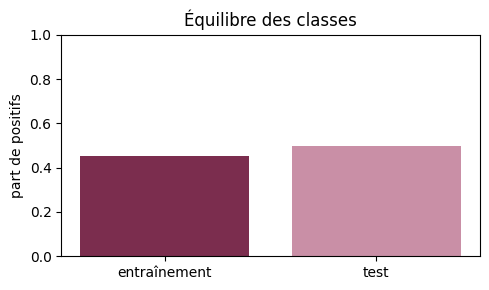

In [2]:
train_rows, test_rows = load_split()
X_train, y_train = design_matrix(train_rows), labels(train_rows)
X_test, y_test = design_matrix(test_rows), labels(test_rows)
groups = [row["user_id"] for row in train_rows]

summary = pd.DataFrame(
    {
        "lignes": [len(y_train), len(y_test)],
        "utilisateurs": [len(set(groups)), len({r["user_id"] for r in test_rows})],
        "part de positifs": [round(float(y_train.mean()), 3), round(float(y_test.mean()), 3)],
    },
    index=["entraînement", "test"],
)
print(summary)

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(summary.index, summary["part de positifs"], color=["#7b2d4e", "#c98fa6"])
ax.set_ylabel("part de positifs")
ax.set_title("Équilibre des classes")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## 2. Les caractéristiques

Quatre signaux de **contenu** sont appris : `skin_match`, `finish_match`, `budget_score`, `availability`.

Deux signaux restent **fixes** : `interaction` et `history_match`. Ils sont calculés à partir des interactions passées, donc des mêmes labels que ceux à prédire. Les apprendre reviendrait à donner la réponse au modèle (fuite de cible). Les garder fixes est un choix assumé.

In [3]:
profil = pd.DataFrame(X_train, columns=CONTENT_FEATURES)
profil["label"] = y_train
print("Moyenne de chaque signal selon le label (0 = non retenu, 1 = positif) :")
print(profil.groupby("label")[CONTENT_FEATURES].mean().round(3))

Moyenne de chaque signal selon le label (0 = non retenu, 1 = positif) :
       skin_match  finish_match  budget_score  availability
label                                                      
0           0.247         0.301         0.368         0.932
1           0.433         0.533         0.422         0.933


## 3. Point de départ : les poids fixés à la main

C'est la référence à battre. L'AUC mesure la capacité du score à classer un produit positif avant un produit non positif (0,5 = hasard, 1 = parfait). Elle est calculée ici sur le jeu de test, que le modèle n'a jamais vu.

In [4]:
manual = dict(engine.DEFAULT_SCORE_WEIGHTS)
manual_auc = content_auc(manual, X_test, y_test)
print("Poids manuels :", manual)
print(f"AUC de contenu sur le test : {manual_auc:.4f}")

Poids manuels : {'skin_match': 0.25, 'finish_match': 0.2, 'budget_score': 0.2, 'availability': 0.1, 'interaction': 0.15, 'history_match': 0.1}
AUC de contenu sur le test : 0.6813


## 4. Choix de la régularisation par validation croisée groupée

Le paramètre `C` règle la force de la régularisation (plus il est petit, plus le modèle est prudent). On le choisit par validation croisée **groupée par utilisateur** (des utilisateurs entiers sont mis de côté à chaque tour, ce qui est plus exigeant que le découpage ci-dessus), uniquement sur l'entraînement. Le test n'intervient pas dans ce choix.

C retenu : 1.0 (AUC de validation croisée : 0.6884)


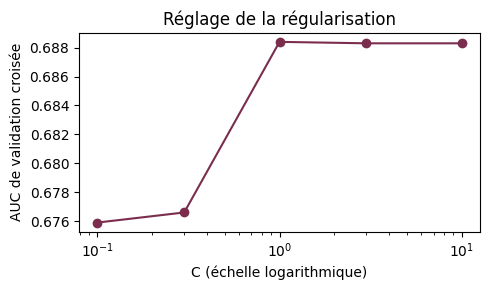

In [5]:
best_c, best_cv_auc, cv_scores = choose_regularisation(X_train, y_train, groups)
print(f"C retenu : {best_c} (AUC de validation croisée : {best_cv_auc:.4f})")

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot([float(c) for c in cv_scores], list(cv_scores.values()), marker="o", color="#7b2d4e")
ax.set_xscale("log")
ax.set_xlabel("C (échelle logarithmique)")
ax.set_ylabel("AUC de validation croisée")
ax.set_title("Réglage de la régularisation")
plt.tight_layout()
plt.show()

## 5. Apprentissage du candidat

Les coefficients de la régression logistique sont ramenés à des **poids** (part du score), de sorte que le modèle reste lisible : on peut toujours expliquer à l'utilisateur pourquoi un produit est recommandé. Les coefficients négatifs sont ramenés à zéro et la somme des poids reste égale à 1.

Coefficients bruts : {'skin_match': 1.064, 'finish_match': 1.126, 'budget_score': 0.7201, 'availability': 0.1847}
Poids du candidat  : {'skin_match': 0.2579, 'finish_match': 0.2728, 'budget_score': 0.1745, 'availability': 0.0448, 'interaction': 0.15, 'history_match': 0.1}
Somme des poids    : 1.0


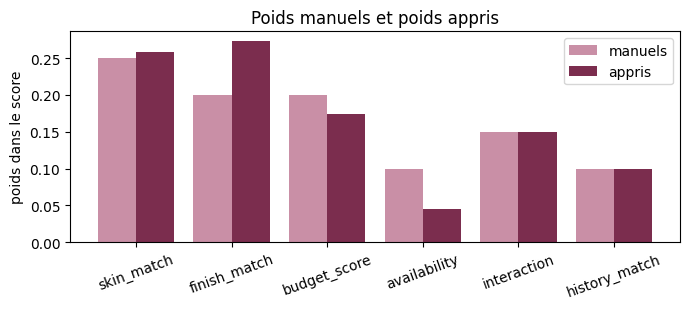

In [6]:
fixed = {name: manual[name] for name in FIXED_FEATURES}
fitted = fit_candidate(X_train, y_train, groups, fixed)
candidate_weights = fitted["weights"]
print("Coefficients bruts :", fitted["learned"]["coefficients"])
print("Poids du candidat  :", candidate_weights)
print("Somme des poids    :", round(sum(candidate_weights.values()), 4))

names = CONTENT_FEATURES + FIXED_FEATURES
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(x - 0.2, [manual[n] for n in names], 0.4, label="manuels", color="#c98fa6")
ax.bar(x + 0.2, [candidate_weights[n] for n in names], 0.4, label="appris", color="#7b2d4e")
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=20)
ax.set_ylabel("poids dans le score")
ax.legend()
ax.set_title("Poids manuels et poids appris")
plt.tight_layout()
plt.show()

## 6. Le candidat est-il vraiment meilleur ?

Avec 40 lignes de test, un petit écart d'AUC peut venir du hasard. On mesure donc l'incertitude par **rééchantillonnage** (bootstrap) : on retire 1 000 fois des lignes de test avec remise et on regarde la différence d'AUC entre le candidat et les poids manuels.

Écart d'AUC observé (candidat moins manuel) : -0.0025
Intervalle de confiance à 95 % : [-0.0682 ; +0.0601]
Zéro est dans l'intervalle : l'écart n'est pas significatif.


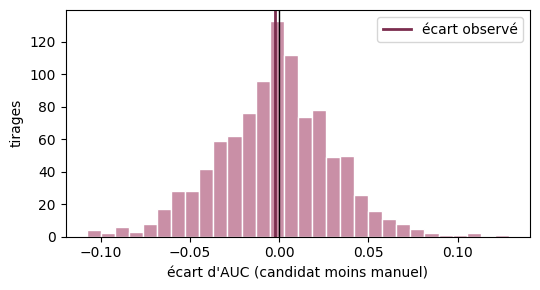

In [7]:
rng = np.random.default_rng(42)
vec_manual = np.array([manual[n] for n in CONTENT_FEATURES])
vec_cand = np.array([candidate_weights[n] for n in CONTENT_FEATURES])
from sklearn.metrics import roc_auc_score

diffs = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if len(set(y_test[idx])) < 2:
        continue
    a_cand = roc_auc_score(y_test[idx], X_test[idx] @ vec_cand)
    a_manu = roc_auc_score(y_test[idx], X_test[idx] @ vec_manual)
    diffs.append(a_cand - a_manu)

low, high = np.percentile(diffs, [2.5, 97.5])
observed = content_auc(candidate_weights, X_test, y_test) - manual_auc
print(f"Écart d'AUC observé (candidat moins manuel) : {observed:+.4f}")
print(f"Intervalle de confiance à 95 % : [{low:+.4f} ; {high:+.4f}]")
print("Zéro est dans l'intervalle : l'écart n'est pas significatif." if low <= 0 <= high
      else "Zéro est hors de l'intervalle : l'écart est significatif.")

fig, ax = plt.subplots(figsize=(5.5, 3))
ax.hist(diffs, bins=30, color="#c98fa6", edgecolor="white")
ax.axvline(0, color="black", linewidth=1)
ax.axvline(observed, color="#7b2d4e", linewidth=2, label="écart observé")
ax.set_xlabel("écart d'AUC (candidat moins manuel)")
ax.set_ylabel("tirages")
ax.legend()
plt.tight_layout()
plt.show()

## 7. La décision de promotion

Un candidat n'est promu que s'il passe **trois garde-fous**, dans cet ordre :

1. aucune règle métier critique n'est violée (budget, compatibilité, disponibilité, explications, doublons, nombre de produits) ;
2. la précision fonctionnelle ne baisse pas de plus de 0,02 ;
3. l'AUC de contenu gagne au moins 0,01.

C'est exactement la fonction `decide()` utilisée par le réentraînement automatique et par la CI.

In [8]:
active_metrics = evaluate(manual, X_test, y_test)
candidate_metrics = evaluate(candidate_weights, X_test, y_test)
decision = decide(candidate_metrics, active_metrics)

table = pd.DataFrame(
    {
        "AUC de contenu": [active_metrics["content_auc_test"], candidate_metrics["content_auc_test"]],
        "précision fonctionnelle": [active_metrics["precision_functional"], candidate_metrics["precision_functional"]],
        "hit rate": [active_metrics["hit_functional"], candidate_metrics["hit_functional"]],
    },
    index=["modèle actif (manuel)", "candidat (appris)"],
)
print(table)
print()
print("Règles métier critiques du candidat :", candidate_metrics["critical"])
print()
print("PROMU" if decision["promote"] else "NON PROMU", ":", decision["reason"])

                       AUC de contenu  précision fonctionnelle  hit rate
modèle actif (manuel)          0.6813                   0.1625      0.65
candidat (appris)              0.6788                   0.1625      0.65

Règles métier critiques du candidat : {'budget_compliance': 1.0, 'compatibility_rate': 1.0, 'availability_rate': 1.0, 'explanation_coverage': 1.0, 'no_duplicates_rate': 1.0, 'max_products_respected_rate': 1.0}

NON PROMU : gain d'AUC insuffisant (-0.0025 pour un minimum de +0.01)


## 8. Surveillance de la dérive des données

Une fois le modèle en production, on compare la distribution des données courantes à celle de l'entraînement avec l'indice **PSI** (Population Stability Index) : sous 0,10 c'est stable, entre 0,10 et 0,25 il faut surveiller, à partir de 0,25 c'est une dérive qui déclenche un réentraînement.

La deuxième mesure utilise des données **volontairement décalées** (budgets serrés, stocks bas) pour montrer que le détecteur réagit.

Données courantes : stable (PSI max 0.0085 )
Données décalées  : drift (PSI max 4.2291 )


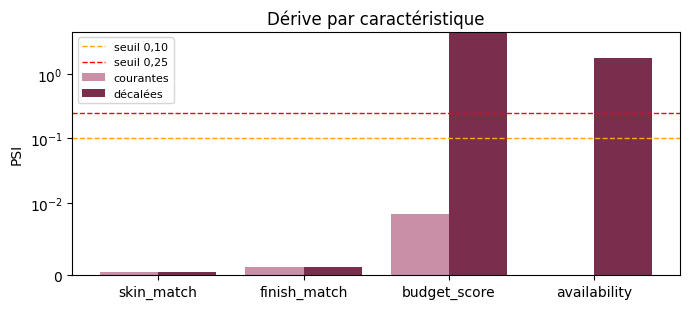

In [9]:
reference = build_reference(X_train, CONTENT_FEATURES)
X_now = design_matrix(train_rows + test_rows)
normal = compute_drift(reference, X_now, CONTENT_FEATURES)
shifted = compute_drift(reference, simulate_shift(X_now, CONTENT_FEATURES), CONTENT_FEATURES)
print("Données courantes :", normal["status"], "(PSI max", normal["max_psi"], ")")
print("Données décalées  :", shifted["status"], "(PSI max", shifted["max_psi"], ")")

x = np.arange(len(CONTENT_FEATURES))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(x - 0.2, [normal["features"][n]["psi"] for n in CONTENT_FEATURES], 0.4, label="courantes", color="#c98fa6")
ax.bar(x + 0.2, [shifted["features"][n]["psi"] for n in CONTENT_FEATURES], 0.4, label="décalées", color="#7b2d4e")
ax.axhline(0.10, color="orange", linestyle="--", linewidth=1, label="seuil 0,10")
ax.axhline(0.25, color="red", linestyle="--", linewidth=1, label="seuil 0,25")
ax.set_yscale("symlog", linthresh=0.01)
ax.set_xticks(x)
ax.set_xticklabels(CONTENT_FEATURES)
ax.set_ylabel("PSI")
ax.legend(fontsize=8)
ax.set_title("Dérive par caractéristique")
plt.tight_layout()
plt.show()

## 9. Conclusions et limites

- La chaîne complète est en place : apprentissage, évaluation sur un test jamais vu, comparaison au modèle actif, décision automatique, détection de dérive.
- La décision de promotion (section 7) est **calculée**, pas écrite à la main : si le candidat n'apporte pas un gain suffisant, le système conserve le modèle actif. Un refus est un résultat normal et attendu d'un système de réentraînement prudent.
- L'écart entre candidat et poids manuels est à lire avec son intervalle de confiance (section 6).

**Limites assumées**

- Données synthétiques : les performances ne se transposent pas à des utilisateurs réels.
- Peu de lignes de test (40) : les mesures sont bruitées, d'où le bootstrap.
- Les mêmes utilisateurs apparaissent en entraînement et en test : le test ne mesure pas la généralisation à de nouveaux utilisateurs.
- Seuls quatre poids sur six sont appris (voir section 2).
- L'évaluation fonctionnelle est en partie circulaire (les règles métier servent à la fois à recommander et à évaluer) : elle sert de garde-fou, pas de preuve de pertinence réelle.